In [1]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

BASE = Path("/home/ibm-user/shared/ColdGuardian_AI")

files = {
    "Shipments": "shipments.csv",
    "Facilities": "facilities.csv",
    "Sensor Readings": "sensor_readings.csv",
    "Sensor Quality": "sensor_quality_report.csv",
    "Rescue Decisions": "rescue_decision_report.csv",
    "Integrated Report": "coldguardian_integrated_report.csv",
}

data = {}

for name, filename in files.items():
    path = BASE / filename
    if path.exists():
        data[name] = pd.read_csv(path)
        print(f"Loaded {name}: {len(data[name])} rows")
    else:
        print(f"Missing file: {path}")

display(Markdown("# ColdGuardian AI — Cold-Chain Monitoring"))

for name, df in data.items():
    display(Markdown(f"## {name}"))
    display(df.head(10))


Loaded Shipments: 3 rows
Loaded Facilities: 3 rows
Loaded Sensor Readings: 12 rows
Loaded Sensor Quality: 3 rows
Loaded Rescue Decisions: 3 rows
Loaded Integrated Report: 3 rows


# ColdGuardian AI — Cold-Chain Monitoring

## Shipments

,shipment_id,product,min_temp_c,max_temp_c,current_temp_c,inventory_units,priority
0,SH001,Vaccine-A,2.0,8.0,10.2,240,High
1,SH002,Medicine-B,2.0,8.0,6.5,120,Medium
2,SH003,Vaccine-A,2.0,8.0,8.7,180,High


## Facilities

...

,shipment_id,product,min_temp_c,max_temp_c,current_temp_c,inventory_units,priority,timestamp,temperature_c,data_source,reading_age_min,data_quality_status
0,SH001,Vaccine-A,2.0,8.0,10.2,240,High,2026-10-17 08:55:00,10.2,SYNTHETIC_DEMO,0.0,TEMPERATURE ABOVE MAX
1,SH002,Medicine-B,2.0,8.0,6.5,120,Medium,NaN,NaN,NaN,NaN,MISSING READING
2,SH003,Vaccine-A,2.0,8.0,8.7,180,High,NaN,NaN,NaN,NaN,MISSING READING


## Rescue Decisions

,shipment_id,status,priority,recommended_facility,travel_time_min,reason,human_approval
0,SH001,TEMPERATURE EXCURSION,URGENT,Central Health Centre,25.0,Temperature 10.2°C is outside configured limit...,REQUIRED
1,SH002,VERIFY SENSOR / ESCALATE,HIGH,Not assigned,NaN,No sensor reading available; verify shipment c...,REQUIRED
2,SH003,VERIFY SENSOR / ESCALATE,HIGH,Not assigned,NaN,No sensor reading available; verify shipment c...,REQUIRED


## Integrated Report

,shipment_id,product,min_temp_c,max_temp_c,current_temp_c,inventory_units,temperature_c,timestamp,data_quality_status,status,priority,recommended_facility,travel_time_min,reason,human_approval,threshold_state,recent_trend
0,SH001,Vaccine-A,2.0,8.0,10.2,240,10.2,2026-10-17 08:55:00,TEMPERATURE ABOVE MAX,TEMPERATURE EXCURSION,URGENT,Central Health Centre,25.0,Temperature 10.2°C is outside configured limit...,REQUIRED,ABOVE UPPER LIMIT,0.094 °C/min (experimental)
1,SH002,Medicine-B,2.0,8.0,6.5,120,NaN,NaN,MISSING READING,VERIFY SENSOR / ESCALATE,HIGH,Not assigned,NaN,No sensor reading available; verify shipment c...,REQUIRED,MISSING SENSOR DATA,INSUFFICIENT DATA
2,SH003,Vaccine-A,2.0,8.0,8.7,180,NaN,NaN,MISSING READING,VERIFY SENSOR / ESCALATE,HIGH,Not assigned,NaN,No sensor reading available; verify shipment c...,REQUIRED,MISSING SENSOR DATA,INSUFFICIENT DATA


### Live demo overview

**Demo-data notice:** These are synthetic sample records, not live sensor telemetry. Flagged inventory is not necessarily unusable; follow validated cold-chain procedures and obtain qualified human approval.

### 1. Shipment incident board

,Shipment,Product,Current °C,Min °C,Max °C,Units,Status,Priority
0,SH001,Vaccine-A,10.2,2.0,8.0,240,TEMPERATURE EXCURSION,URGENT
1,SH002,Medicine-B,6.5,2.0,8.0,120,VERIFY SENSOR,HIGH
2,SH003,Vaccine-A,8.7,2.0,8.0,180,VERIFY SENSOR,HIGH


### 2. Sensor temperature trend

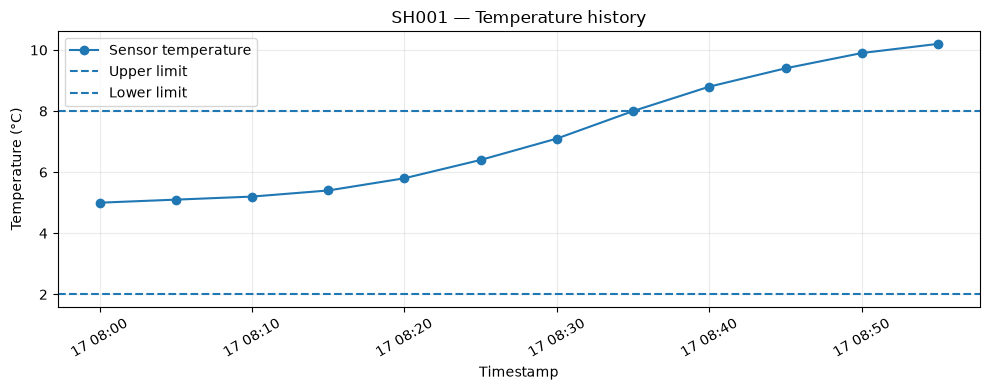

### 3. Rescue decision recommendations

,shipment_id,status,priority,recommended_facility,travel_time_min,reason,human_approval
0,SH001,TEMPERATURE EXCURSION,URGENT,Central Health Centre,25.0,Temperature 10.2°C is outside configured limit...,REQUIRED
1,SH002,VERIFY SENSOR / ESCALATE,HIGH,Not assigned,NaN,No sensor reading available; verify shipment c...,REQUIRED
2,SH003,VERIFY SENSOR / ESCALATE,HIGH,Not assigned,NaN,No sensor reading available; verify shipment c...,REQUIRED


### 4. Downloadable incident report

Report saved to: /home/ibm-user/shared/ColdGuardian_AI/coldguardian_dashboard_incidents.csv


The incident report is saved in your project folder. You can download `coldguardian_dashboard_incidents.csv` from the JupyterLab file browser.

In [2]:

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from IPython.display import HTML

# Use the data already loaded in the previous cell
shipments = data["Shipments"].copy()
readings = data["Sensor Readings"].copy()
facilities = data["Facilities"].copy()
report = data["Integrated Report"].copy()

# Ensure numeric fields are usable
for col in ["min_temp_c", "max_temp_c", "current_temp_c", "inventory_units"]:
    shipments[col] = pd.to_numeric(shipments[col], errors="coerce")

# Create dashboard status from the configured limits and sensor-quality report
quality = data["Sensor Quality"].set_index("shipment_id")

def classify(row):
    sid = row["shipment_id"]
    quality_status = quality.loc[sid, "data_quality_status"] if sid in quality.index else "UNKNOWN"

    if quality_status == "MISSING READING":
        return "VERIFY SENSOR", "HIGH"
    if row["current_temp_c"] > row["max_temp_c"]:
        return "TEMPERATURE EXCURSION", "URGENT"
    if row["current_temp_c"] < row["min_temp_c"]:
        return "TEMPERATURE EXCURSION", "URGENT"
    return "WITHIN LIMITS", "NORMAL"

classifications = shipments.apply(classify, axis=1, result_type="expand")
shipments["incident_status"] = classifications[0]
shipments["incident_priority"] = classifications[1]

urgent_count = (shipments["incident_priority"] == "URGENT").sum()
verify_count = (shipments["incident_status"] == "VERIFY SENSOR").sum()
safe_count = (shipments["incident_status"] == "WITHIN LIMITS").sum()
inventory_at_risk = shipments.loc[
    shipments["incident_status"] != "WITHIN LIMITS", "inventory_units"
].sum()

display(HTML("""
<div style="background:#10243A;color:white;padding:22px;border-radius:12px;">
<h1 style="margin:0;">🧊 ColdGuardian AI</h1>
<p style="margin:8px 0 0 0;">Cold-chain risk monitoring and rescue decision support</p>
</div>
"""))

display(Markdown("### Live demo overview"))
display(HTML(f"""
<div style="display:flex;flex-wrap:wrap;gap:12px;margin:12px 0;">
  <div style="padding:16px;border:1px solid #dc2626;border-radius:10px;min-width:140px;">
    <b>Urgent excursions</b><h2 style="margin:5px 0;color:#dc2626">{urgent_count}</h2>
  </div>
  <div style="padding:16px;border:1px solid #d97706;border-radius:10px;min-width:140px;">
    <b>Sensor verification</b><h2 style="margin:5px 0;color:#d97706">{verify_count}</h2>
  </div>
  <div style="padding:16px;border:1px solid #16a34a;border-radius:10px;min-width:140px;">
    <b>Within limits</b><h2 style="margin:5px 0;color:#16a34a">{safe_count}</h2>
  </div>
  <div style="padding:16px;border:1px solid #64748b;border-radius:10px;min-width:140px;">
    <b>Units in flagged shipments</b><h2 style="margin:5px 0">{int(inventory_at_risk)}</h2>
  </div>
</div>
"""))

display(Markdown(
    "**Demo-data notice:** These are synthetic sample records, not live sensor telemetry. "
    "Flagged inventory is not necessarily unusable; follow validated cold-chain procedures "
    "and obtain qualified human approval."
))

display(Markdown("### 1. Shipment incident board"))

board = shipments[
    ["shipment_id", "product", "current_temp_c", "min_temp_c",
     "max_temp_c", "inventory_units", "incident_status", "incident_priority"]
].copy()

board = board.rename(columns={
    "shipment_id": "Shipment",
    "product": "Product",
    "current_temp_c": "Current °C",
    "min_temp_c": "Min °C",
    "max_temp_c": "Max °C",
    "inventory_units": "Units",
    "incident_status": "Status",
    "incident_priority": "Priority"
})

display(board.sort_values(
    "Priority", key=lambda s: s.map({"URGENT": 0, "HIGH": 1, "NORMAL": 2})
).reset_index(drop=True))

display(Markdown("### 2. Sensor temperature trend"))

readings["timestamp"] = pd.to_datetime(readings["timestamp"], errors="coerce")
readings["temperature_c"] = pd.to_numeric(readings["temperature_c"], errors="coerce")

shipment_choices = sorted(readings["shipment_id"].dropna().unique().tolist())

if shipment_choices:
    for sid in shipment_choices:
        subset = readings[readings["shipment_id"] == sid].dropna(
            subset=["timestamp", "temperature_c"]
        ).sort_values("timestamp")

        shipment_row = shipments[shipments["shipment_id"] == sid]
        if subset.empty:
            continue

        upper_limit = (
            float(shipment_row["max_temp_c"].iloc[0])
            if not shipment_row.empty else 8.0
        )
        lower_limit = (
            float(shipment_row["min_temp_c"].iloc[0])
            if not shipment_row.empty else 2.0
        )

        plt.figure(figsize=(10, 4))
        plt.plot(subset["timestamp"], subset["temperature_c"],
                 marker="o", label="Sensor temperature")
        plt.axhline(upper_limit, linestyle="--", label="Upper limit")
        plt.axhline(lower_limit, linestyle="--", label="Lower limit")
        plt.title(f"{sid} — Temperature history")
        plt.xlabel("Timestamp")
        plt.ylabel("Temperature (°C)")
        plt.xticks(rotation=30)
        plt.legend()
        plt.grid(True, alpha=0.25)
        plt.tight_layout()
        plt.show()

display(Markdown("### 3. Rescue decision recommendations"))

rescue = data["Rescue Decisions"].copy()
display(rescue)

display(Markdown("### 4. Downloadable incident report"))

export_path = BASE / "coldguardian_dashboard_incidents.csv"
board.to_csv(export_path, index=False)
print(f"Report saved to: {export_path}")

display(Markdown(
    "The incident report is saved in your project folder. "
    "You can download `coldguardian_dashboard_incidents.csv` from the JupyterLab file browser."
))


# ColdGuardian AI — Explainable Risk Engine

Scores are transparent prototype heuristics, not validated clinical or regulatory thresholds. Missing data is treated as a verification risk.

,shipment_id,product,current_temp_c,allowed_range_c,inventory_units,severity_score,severity_level,temperature_points,sensor_quality_points,inventory_impact_points,persistence_points,explanation
0,SH001,Vaccine-A,10.2,2.0–8.0,240,47,HIGH,15,0,20,12,2.2°C outside configured range | Sensor qualit...
1,SH003,Vaccine-A,8.7,2.0–8.0,180,42,HIGH — VERIFY,5,25,12,0,0.7°C outside configured range | Missing senso...
2,SH002,Medicine-B,6.5,2.0–8.0,120,37,HIGH — VERIFY,0,25,12,0,Current reported temperature within range | Mi...


## Rescue planner

,shipment_id,facility,eligible,travel_time_min,decision,reason
0,SH001,Central Health Centre,True,25.0,CANDIDATE — HUMAN APPROVAL REQUIRED,Compatible storage and sufficient capacity; ra...
1,SH002,Not assigned,False,NaN,VERIFY SENSOR / ESCALATE,No sensor reading available; verify shipment a...
2,SH003,Not assigned,False,NaN,VERIFY SENSOR / ESCALATE,No sensor reading available; verify shipment a...


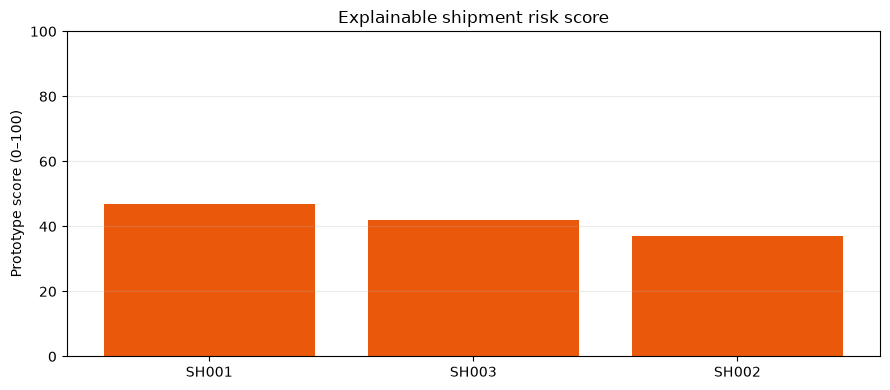

Saved: /home/ibm-user/shared/ColdGuardian_AI/coldguardian_severity_report.csv
Saved: /home/ibm-user/shared/ColdGuardian_AI/coldguardian_rescue_plan.csv
Open the ColdGuardian_AI folder in JupyterLab to download both CSV reports.


In [3]:

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML

# Reuse the existing data dictionary and BASE path
shipments = pd.read_csv(BASE / "shipments.csv")
facilities = pd.read_csv(BASE / "facilities.csv")
readings = pd.read_csv(BASE / "sensor_readings.csv")
quality = pd.read_csv(BASE / "sensor_quality_report.csv")

for col in ["min_temp_c", "max_temp_c", "current_temp_c", "inventory_units"]:
    shipments[col] = pd.to_numeric(shipments[col], errors="coerce")

for col in ["temperature_c"]:
    readings[col] = pd.to_numeric(readings[col], errors="coerce")

readings["timestamp"] = pd.to_datetime(readings["timestamp"], errors="coerce")

# ---- 1. Explainable severity scoring ----
# This is a transparent rule-based prototype, NOT a trained ML model.
# Scores are demonstration decision-support scores and need domain validation.

quality_lookup = quality.set_index("shipment_id")["data_quality_status"].to_dict()
severity_rows = []

for _, s in shipments.iterrows():
    sid = s["shipment_id"]
    current = s["current_temp_c"]
    low = s["min_temp_c"]
    high = s["max_temp_c"]
    inventory = s["inventory_units"]
    quality_status = quality_lookup.get(sid, "UNKNOWN")

    if pd.isna(current) or pd.isna(low) or pd.isna(high):
        deviation = None
        deviation_points = 0
        temp_reason = "Temperature unavailable"
    else:
        deviation = max(low - current, current - high, 0)
        deviation_points = min(40, round((deviation / max(high - low, 1)) * 40))
        temp_reason = (
            f"{deviation:.1f}°C outside configured range"
            if deviation > 0 else "Current reported temperature within range"
        )

    # Sensor-quality risk: missing or unreliable data requires verification.
    missing_sensor = quality_status == "MISSING READING"
    quality_points = 25 if missing_sensor else 0

    # Inventory is an impact proxy, not evidence of product damage.
    inventory_points = (
        20 if inventory >= 200 else
        12 if inventory >= 100 else
        5
    )

    # SH001 has 12 readings; use actual sequence to estimate persistence.
    history = readings[readings["shipment_id"] == sid].dropna(
        subset=["timestamp", "temperature_c"]
    ).sort_values("timestamp")

    if not history.empty and not pd.isna(high):
        above = history["temperature_c"] > high
        persistence_points = min(15, int(above.sum()) * 3)
        persistence_reason = f"{int(above.sum())} readings above upper limit"
    else:
        persistence_points = 0
        persistence_reason = "Insufficient sensor history"

    score = min(100, deviation_points + quality_points +
                inventory_points + persistence_points)

    if missing_sensor:
        level = "HIGH — VERIFY"
    elif deviation is not None and deviation >= 4:
        level = "CRITICAL"
    elif deviation is not None and deviation > 0:
        level = "HIGH"
    elif score >= 40:
        level = "MEDIUM"
    else:
        level = "LOW"

    reasons = [
        temp_reason,
        "Missing sensor reading — verify immediately" if missing_sensor
        else "Sensor quality report contains a reading",
        f"{int(inventory) if not pd.isna(inventory) else 0} units in shipment (impact proxy)",
        persistence_reason
    ]

    severity_rows.append({
        "shipment_id": sid,
        "product": s["product"],
        "current_temp_c": current,
        "allowed_range_c": f"{low}–{high}",
        "inventory_units": inventory,
        "severity_score": score,
        "severity_level": level,
        "temperature_points": deviation_points,
        "sensor_quality_points": quality_points,
        "inventory_impact_points": inventory_points,
        "persistence_points": persistence_points,
        "explanation": " | ".join(reasons)
    })

severity = pd.DataFrame(severity_rows).sort_values(
    "severity_score", ascending=False
).reset_index(drop=True)

display(Markdown("# ColdGuardian AI — Explainable Risk Engine"))
display(Markdown(
    "Scores are transparent prototype heuristics, not validated clinical or "
    "regulatory thresholds. Missing data is treated as a verification risk."
))
display(severity)

# ---- 2. Facility eligibility and rescue ranking ----
facility_rows = []

for _, s in shipments.iterrows():
    sid = s["shipment_id"]
    units = s["inventory_units"]
    current = s["current_temp_c"]
    low = s["min_temp_c"]
    high = s["max_temp_c"]
    qstatus = quality_lookup.get(sid, "UNKNOWN")

    # Rescue is suggested only for a reported temperature excursion.
    excursion = (
        pd.notna(current) and pd.notna(low) and pd.notna(high)
        and (current < low or current > high)
    )

    if qstatus == "MISSING READING":
        facility_rows.append({
            "shipment_id": sid,
            "facility": "Not assigned",
            "eligible": False,
            "travel_time_min": None,
            "decision": "VERIFY SENSOR / ESCALATE",
            "reason": "No sensor reading available; verify shipment and sensor."
        })
        continue

    if not excursion:
        facility_rows.append({
            "shipment_id": sid,
            "facility": "No transfer recommended yet",
            "eligible": False,
            "travel_time_min": None,
            "decision": "MONITOR",
            "reason": "No confirmed excursion in the available report."
        })
        continue

    eligible = facilities[
        facilities["compatible_storage"].astype(str).str.lower().isin(["true", "1"])
        & (pd.to_numeric(facilities["spare_capacity_units"], errors="coerce") >= units)
    ].copy()

    if eligible.empty:
        facility_rows.append({
            "shipment_id": sid,
            "facility": "No eligible facility",
            "eligible": False,
            "travel_time_min": None,
            "decision": "HUMAN ESCALATION",
            "reason": "No compatible facility with sufficient spare capacity."
        })
        continue

    eligible["travel_time_min"] = pd.to_numeric(
        eligible["travel_time_min"], errors="coerce"
    )
    eligible = eligible.sort_values("travel_time_min")
    chosen = eligible.iloc[0]

    facility_rows.append({
        "shipment_id": sid,
        "facility": chosen["name"],
        "eligible": True,
        "travel_time_min": chosen["travel_time_min"],
        "decision": "CANDIDATE — HUMAN APPROVAL REQUIRED",
        "reason": (
            "Compatible storage and sufficient capacity; "
            "ranked by shortest reported travel time."
        )
    })

rescue_plan = pd.DataFrame(facility_rows)

display(Markdown("## Rescue planner"))
display(rescue_plan)

# ---- 3. Explainable priority chart ----
plt.figure(figsize=(9, 4))
colors = [
    "#dc2626" if level == "CRITICAL" else
    "#ea580c" if level.startswith("HIGH") else
    "#ca8a04" if level == "MEDIUM" else "#16a34a"
    for level in severity["severity_level"]
]
plt.bar(severity["shipment_id"], severity["severity_score"], color=colors)
plt.ylim(0, 100)
plt.ylabel("Prototype score (0–100)")
plt.title("Explainable shipment risk score")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# ---- 4. Export the results ----
severity_path = BASE / "coldguardian_severity_report.csv"
rescue_path = BASE / "coldguardian_rescue_plan.csv"

severity.to_csv(severity_path, index=False)
rescue_plan.to_csv(rescue_path, index=False)

print("Saved:", severity_path)
print("Saved:", rescue_path)
print("Open the ColdGuardian_AI folder in JupyterLab to download both CSV reports.")


In [4]:

# ColdGuardian AI — Clearer incident classification

def classify_incident(row):
    sid = row["shipment_id"]
    temp = row["current_temp_c"]
    low = row["min_temp_c"]
    high = row["max_temp_c"]
    quality_status = quality_lookup.get(sid, "UNKNOWN")

    if quality_status == "MISSING READING":
        return pd.Series({
            "temperature_status": "UNCONFIRMED — SENSOR DATA MISSING",
            "data_quality_risk": "HIGH",
            "recommended_action": "Verify sensor, check physical shipment, escalate"
        })

    if pd.isna(temp) or pd.isna(low) or pd.isna(high):
        return pd.Series({
            "temperature_status": "UNKNOWN",
            "data_quality_risk": "HIGH",
            "recommended_action": "Obtain a valid temperature reading"
        })

    if temp > high:
        return pd.Series({
            "temperature_status": "ABOVE UPPER LIMIT",
            "data_quality_risk": "READING AVAILABLE",
            "recommended_action": "Initiate cold-chain excursion SOP; human review required"
        })

    if temp < low:
        return pd.Series({
            "temperature_status": "BELOW LOWER LIMIT",
            "data_quality_risk": "READING AVAILABLE",
            "recommended_action": "Initiate cold-chain excursion SOP; human review required"
        })

    return pd.Series({
        "temperature_status": "WITHIN CONFIGURED RANGE",
        "data_quality_risk": "READING AVAILABLE",
        "recommended_action": "Continue monitoring"
    })


classification = shipments.apply(classify_incident, axis=1)
improved_report = pd.concat([shipments, classification], axis=1)

display(Markdown("## ColdGuardian AI — Incident classification"))
display(improved_report[[
    "shipment_id", "product", "current_temp_c",
    "temperature_status", "data_quality_risk", "recommended_action"
]])

improved_path = BASE / "coldguardian_improved_incident_report.csv"
improved_report.to_csv(improved_path, index=False)

print(f"Saved: {improved_path}")


## ColdGuardian AI — Incident classification

,shipment_id,product,current_temp_c,temperature_status,data_quality_risk,recommended_action
0,SH001,Vaccine-A,10.2,ABOVE UPPER LIMIT,READING AVAILABLE,Initiate cold-chain excursion SOP; human revie...
1,SH002,Medicine-B,6.5,UNCONFIRMED — SENSOR DATA MISSING,HIGH,"Verify sensor, check physical shipment, escalate"
2,SH003,Vaccine-A,8.7,UNCONFIRMED — SENSOR DATA MISSING,HIGH,"Verify sensor, check physical shipment, escalate"


Saved: /home/ibm-user/shared/ColdGuardian_AI/coldguardian_improved_incident_report.csv


In [5]:

import pandas as pd
from IPython.display import display, Markdown, clear_output
import ipywidgets as widgets

display(Markdown("# ColdGuardian AI — What-if Risk Simulator"))
display(Markdown(
    "Experiment with hypothetical shipment conditions. "
    "Results are illustrative decision-support outputs, not predictions of product safety."
))

shipment_options = shipments["shipment_id"].tolist()

shipment_picker = widgets.Dropdown(
    options=shipment_options,
    description="Shipment:",
    layout=widgets.Layout(width="350px")
)

temp_input = widgets.FloatSlider(
    value=10.2, min=-5, max=20, step=0.1,
    description="Temp (°C):",
    readout_format=".1f",
    style={"description_width": "100px"},
    layout=widgets.Layout(width="500px")
)

inventory_input = widgets.IntSlider(
    value=240, min=0, max=500, step=10,
    description="Units:",
    style={"description_width": "100px"},
    layout=widgets.Layout(width="500px")
)

sensor_picker = widgets.Dropdown(
    options=["Reading available", "Sensor missing"],
    value="Reading available",
    description="Sensor:",
    layout=widgets.Layout(width="350px")
)

run_button = widgets.Button(
    description="Assess scenario",
    button_style="primary",
    icon="check"
)

sim_output = widgets.Output()

def update_defaults(change=None):
    row = shipments[shipments["shipment_id"] == shipment_picker.value].iloc[0]
    temp_input.value = float(row["current_temp_c"])
    inventory_input.value = int(row["inventory_units"])
    sensor_picker.value = (
        "Sensor missing"
        if quality_lookup.get(shipment_picker.value) == "MISSING READING"
        else "Reading available"
    )

shipment_picker.observe(update_defaults, names="value")

def assess_scenario(_):
    with sim_output:
        clear_output(wait=True)

        row = shipments[shipments["shipment_id"] == shipment_picker.value].iloc[0]
        temp = temp_input.value
        units = inventory_input.value
        low = float(row["min_temp_c"])
        high = float(row["max_temp_c"])
        sensor_missing = sensor_picker.value == "Sensor missing"

        if sensor_missing:
            display(Markdown("## ⚠️ SENSOR VERIFICATION REQUIRED"))
            display(Markdown(
                "The simulated sensor is missing. Do not treat the entered temperature "
                "as a verified measurement. Check the physical shipment and escalate."
            ))
            status = "UNCONFIRMED — SENSOR DATA MISSING"
        elif temp > high:
            status = "ABOVE UPPER LIMIT"
            display(Markdown("## 🚨 Temperature excursion"))
            display(Markdown(
                f"Simulated temperature is **{temp:.1f}°C**, "
                f"which is **{temp-high:.1f}°C above** the upper limit of {high:.1f}°C."
            ))
            display(Markdown(
                "Follow the validated excursion SOP and obtain qualified human review."
            ))
        elif temp < low:
            status = "BELOW LOWER LIMIT"
            display(Markdown("## 🚨 Temperature excursion"))
            display(Markdown(
                f"Simulated temperature is **{temp:.1f}°C**, "
                f"which is **{low-temp:.1f}°C below** the lower limit of {low:.1f}°C."
            ))
            display(Markdown(
                "Follow the validated excursion SOP and obtain qualified human review."
            ))
        else:
            status = "WITHIN CONFIGURED RANGE"
            display(Markdown("## ✅ Within configured temperature range"))
            display(Markdown(
                f"Simulated temperature is {temp:.1f}°C, within "
                f"the configured range of {low:.1f}–{high:.1f}°C. "
                "Continue monitoring."
            ))

        display(Markdown(f"**Shipment:** {shipment_picker.value}"))
        display(Markdown(f"**Simulated inventory:** {units} units"))
        display(Markdown(f"**Scenario status:** {status}"))
        display(Markdown(
            "**Important:** This simulation changes only the scenario inputs. "
            "It does not change the source CSV files or establish product usability."
        ))

run_button.on_click(assess_scenario)

display(widgets.VBox([
    shipment_picker,
    temp_input,
    inventory_input,
    sensor_picker,
    run_button,
    sim_output
]))

update_defaults()
assess_scenario(None)


# ColdGuardian AI — What-if Risk Simulator

Experiment with hypothetical shipment conditions. Results are illustrative decision-support outputs, not predictions of product safety.

In [6]:

import pandas as pd
from IPython.display import display, Markdown, HTML

# Reload the latest project files
shipments = pd.read_csv(BASE / "shipments.csv")
quality = pd.read_csv(BASE / "sensor_quality_report.csv")
rescue = pd.read_csv(BASE / "coldguardian_rescue_plan.csv")
severity = pd.read_csv(BASE / "coldguardian_severity_report.csv")

# Combine reports using shipment ID
executive = (
    shipments
    .merge(quality[["shipment_id", "data_quality_status"]], on="shipment_id", how="left")
    .merge(
        severity[["shipment_id", "severity_score", "severity_level"]],
        on="shipment_id", how="left"
    )
    .merge(
        rescue[["shipment_id", "facility", "decision", "reason"]],
        on="shipment_id", how="left"
    )
)

def action_for(row):
    if row["data_quality_status"] == "MISSING READING":
        return "Verify sensor and physical shipment; escalate to the responsible team."
    if row["current_temp_c"] > row["max_temp_c"]:
        return "Initiate the validated temperature-excursion SOP; obtain human approval."
    if row["current_temp_c"] < row["min_temp_c"]:
        return "Initiate the validated low-temperature excursion SOP; obtain human approval."
    return "Continue monitoring and verify that sensor readings remain current."

executive["recommended_action"] = executive.apply(action_for, axis=1)

# Present a compact decision table
display(Markdown("# ColdGuardian AI — Executive Decision Report"))
display(Markdown(
    "A consolidated, explainable operational view. "
    "This prototype uses synthetic data and does not authorize shipment disposition."
))

view = executive[[
    "shipment_id", "product", "current_temp_c",
    "data_quality_status", "severity_score", "severity_level",
    "facility", "decision", "recommended_action"
]].copy()

view = view.rename(columns={
    "shipment_id": "Shipment",
    "product": "Product",
    "current_temp_c": "Reported °C",
    "data_quality_status": "Sensor status",
    "severity_score": "Risk score",
    "severity_level": "Risk classification",
    "facility": "Rescue facility",
    "decision": "Rescue decision",
    "recommended_action": "Recommended next action"
})

display(view)

# Save report for judges and review
export_path = BASE / "coldguardian_executive_report.csv"
view.to_csv(export_path, index=False)

display(HTML("""
<div style="padding:16px;border:1px solid #64748b;border-radius:10px;">
<b>Decision safeguards</b>
<ul>
<li>Missing sensor data triggers verification rather than an assumed safe reading.</li>
<li>Incompatible storage facilities are not eligible for rescue recommendations.</li>
<li>Temperature excursions require validated procedures and human approval.</li>
<li>Risk scores are prototype heuristics, not validated predictions of product safety.</li>
</ul>
</div>
"""))

print(f"Executive report saved: {export_path}")


# ColdGuardian AI — Executive Decision Report

A consolidated, explainable operational view. This prototype uses synthetic data and does not authorize shipment disposition.

,Shipment,Product,Reported °C,Sensor status,Risk score,Risk classification,Rescue facility,Rescue decision,Recommended next action
0,SH001,Vaccine-A,10.2,TEMPERATURE ABOVE MAX,47,HIGH,Central Health Centre,CANDIDATE — HUMAN APPROVAL REQUIRED,Initiate the validated temperature-excursion S...
1,SH002,Medicine-B,6.5,MISSING READING,37,HIGH — VERIFY,Not assigned,VERIFY SENSOR / ESCALATE,Verify sensor and physical shipment; escalate ...
2,SH003,Vaccine-A,8.7,MISSING READING,42,HIGH — VERIFY,Not assigned,VERIFY SENSOR / ESCALATE,Verify sensor and physical shipment; escalate ...


Executive report saved: /home/ibm-user/shared/ColdGuardian_AI/coldguardian_executive_report.csv


# ColdGuardian AI — Experimental Forecast

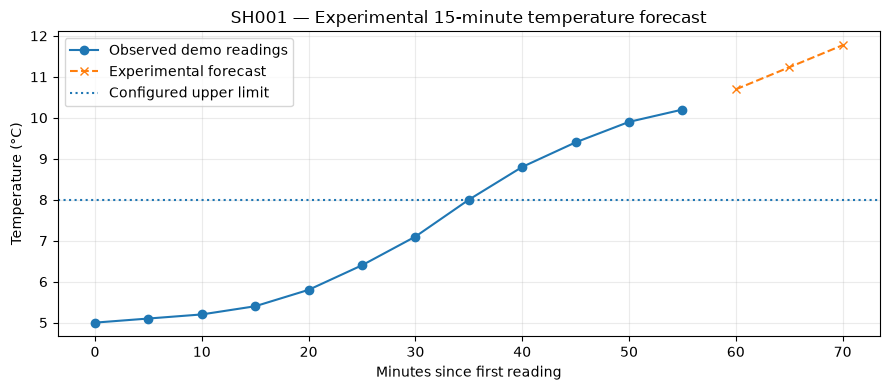

,shipment_id,minutes_ahead,forecast_temperature_c,configured_upper_limit_c,above_limit_in_baseline,trend_c_per_min,model
0,SH001,5,10.69,8.0,True,0.1078,Experimental linear trend
1,SH001,10,11.23,8.0,True,0.1078,Experimental linear trend
2,SH001,15,11.77,8.0,True,0.1078,Experimental linear trend


Forecast saved: /home/ibm-user/shared/ColdGuardian_AI/coldguardian_experimental_forecast.csv


In [7]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

readings = pd.read_csv(BASE / "sensor_readings.csv")
readings["timestamp"] = pd.to_datetime(readings["timestamp"], errors="coerce")
readings["temperature_c"] = pd.to_numeric(
    readings["temperature_c"], errors="coerce"
)

display(Markdown("# ColdGuardian AI — Experimental Forecast"))

forecast_rows = []

for sid, group in readings.groupby("shipment_id"):
    group = group.dropna(subset=["timestamp", "temperature_c"]).sort_values("timestamp")

    if len(group) < 4:
        print(f"{sid}: insufficient readings for the experimental trend forecast.")
        continue

    # Time in minutes since the first observation
    elapsed = (
        group["timestamp"] - group["timestamp"].iloc[0]
    ).dt.total_seconds().to_numpy() / 60

    temps = group["temperature_c"].to_numpy(dtype=float)

    # Linear baseline fit
    slope, intercept = np.polyfit(elapsed, temps, 1)

    last_minute = elapsed[-1]
    future_minutes = np.array([5, 10, 15], dtype=float)
    predicted = intercept + slope * (last_minute + future_minutes)

    shipment = shipments[shipments["shipment_id"] == sid]
    upper_limit = (
        float(shipment["max_temp_c"].iloc[0])
        if not shipment.empty else np.nan
    )

    for horizon, pred in zip(future_minutes, predicted):
        forecast_rows.append({
            "shipment_id": sid,
            "minutes_ahead": int(horizon),
            "forecast_temperature_c": round(float(pred), 2),
            "configured_upper_limit_c": upper_limit,
            "above_limit_in_baseline": (
                bool(pred > upper_limit) if not pd.isna(upper_limit) else None
            ),
            "trend_c_per_min": round(float(slope), 4),
            "model": "Experimental linear trend"
        })

    future_x = last_minute + future_minutes
    plt.figure(figsize=(9, 4))
    plt.plot(elapsed, temps, marker="o", label="Observed demo readings")
    plt.plot(
        future_x, predicted, marker="x", linestyle="--",
        label="Experimental forecast"
    )
    if not pd.isna(upper_limit):
        plt.axhline(upper_limit, linestyle=":", label="Configured upper limit")

    plt.title(f"{sid} — Experimental 15-minute temperature forecast")
    plt.xlabel("Minutes since first reading")
    plt.ylabel("Temperature (°C)")
    plt.legend()
    plt.grid(True, alpha=0.25)
    plt.tight_layout()
    plt.show()

forecast = pd.DataFrame(forecast_rows)

if not forecast.empty:
    display(forecast)
    forecast_path = BASE / "coldguardian_experimental_forecast.csv"
    forecast.to_csv(forecast_path, index=False)
    print(f"Forecast saved: {forecast_path}")
else:
    print("No shipment has enough readings for this baseline forecast.")


**Prototype status:** Synthetic demonstration data. All recommendations require human review; this system does not determine product usability.

## 1. Incident overview

## 2. Explainable incident board

,shipment_id,product,reported_temp_c,min_temp_c,max_temp_c,inventory_units,sensor_quality,incident_status,data_quality_risk,severity_score,severity_label,temperature_points,sensor_quality_points,inventory_impact_points,persistence_points,recommended_action
0,SH001,Vaccine-A,10.2,2.0,8.0,240,TEMPERATURE ABOVE MAX,CONFIRMED BY REPORTED VALUE — REVIEW,READING AVAILABLE,47,HIGH — EXCURSION REVIEW,15,0,20,12,Follow the validated temperature-excursion SOP...
1,SH003,Vaccine-A,8.7,2.0,8.0,180,MISSING READING,VERIFY SENSOR / RECONCILE DATA,HIGH,42,VERIFY — HIGH DATA RISK,5,25,12,0,Verify sensor and physical shipment; reconcile...
2,SH002,Medicine-B,6.5,2.0,8.0,120,MISSING READING,VERIFY SENSOR / RECONCILE DATA,HIGH,37,VERIFY — HIGH DATA RISK,0,25,12,0,Verify sensor and physical shipment; reconcile...


## 3. Rescue planning

,shipment_id,recommended_facility,travel_time_min,decision,reason
0,SH001,Central Health Centre,25.0,CANDIDATE — HUMAN APPROVAL REQUIRED,Compatible storage and sufficient capacity; sh...
1,SH002,Not assigned,NaN,VERIFY SENSOR / ESCALATE,Sensor data is missing; reconcile data before ...
2,SH003,Not assigned,NaN,VERIFY SENSOR / ESCALATE,Sensor data is missing; reconcile data before ...


## 4. Observed temperature history

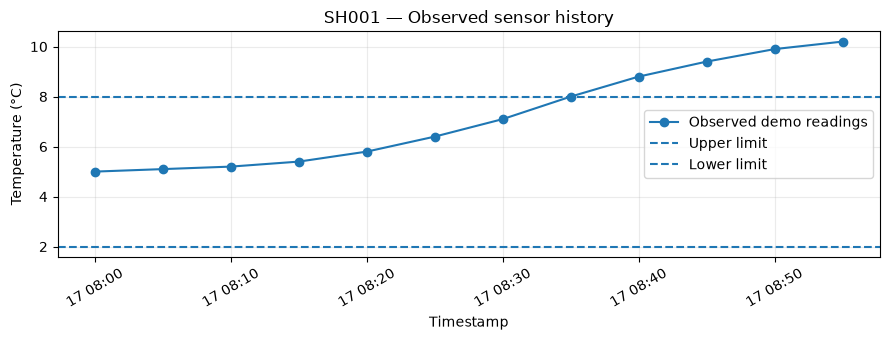

## 5. Experimental forecast

,shipment_id,minutes_ahead,forecast_temperature_c,upper_limit_c,baseline_above_limit,trend_c_per_min,model
0,SH001,5,10.69,8.0,True,0.1078,Experimental linear baseline
1,SH001,10,11.23,8.0,True,0.1078,Experimental linear baseline
2,SH001,15,11.77,8.0,True,0.1078,Experimental linear baseline


Forecasts are short-horizon linear extrapolations from synthetic readings. They are not validated predictions and must not drive automatic decisions.

## 6. Automated validation checks

,Check,Passed
0,Missing sensor cases are not assigned a rescue...,True
1,SH001: assigned facility is compatible and has...,True
2,Severity scores remain between 0 and 100,True


Saved: /home/ibm-user/shared/ColdGuardian_AI/coldguardian_validated_incidents.csv
Saved: /home/ibm-user/shared/ColdGuardian_AI/coldguardian_validated_rescue_plan.csv
Saved: /home/ibm-user/shared/ColdGuardian_AI/coldguardian_validated_forecast.csv
Saved: /home/ibm-user/shared/ColdGuardian_AI/coldguardian_validation_checks.csv


### Demo safeguards
- Synthetic data is not live telemetry.
- A reported temperature and a missing-reading status may conflict; reconcile the source.
- Scores are illustrative heuristics, not a trained or validated AI model.
- Rescue candidates require human approval and real-time operational confirmation.

In [8]:

# ColdGuardian AI — Unified Datathon Dashboard
# Compatible with JupyterLab on IBM LinuxONE.
# Uses existing pandas, numpy and matplotlib installations.

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML

BASE = Path("/home/ibm-user/shared/ColdGuardian_AI")

# ---------- 1. Load and validate source data ----------
shipments = pd.read_csv(BASE / "shipments.csv")
facilities = pd.read_csv(BASE / "facilities.csv")
readings = pd.read_csv(BASE / "sensor_readings.csv")
quality = pd.read_csv(BASE / "sensor_quality_report.csv")

required_shipment_cols = {
    "shipment_id", "product", "min_temp_c", "max_temp_c",
    "current_temp_c", "inventory_units"
}
required_facility_cols = {
    "facility_id", "name", "compatible_storage",
    "spare_capacity_units", "travel_time_min"
}
required_reading_cols = {
    "shipment_id", "timestamp", "temperature_c"
}

assert required_shipment_cols.issubset(shipments.columns), (
    f"Missing shipment columns: {required_shipment_cols - set(shipments.columns)}"
)
assert required_facility_cols.issubset(facilities.columns), (
    f"Missing facility columns: {required_facility_cols - set(facilities.columns)}"
)
assert required_reading_cols.issubset(readings.columns), (
    f"Missing sensor columns: {required_reading_cols - set(readings.columns)}"
)
assert shipments["shipment_id"].is_unique, "Shipment IDs must be unique."

for c in ["min_temp_c", "max_temp_c", "current_temp_c", "inventory_units"]:
    shipments[c] = pd.to_numeric(shipments[c], errors="coerce")

facilities["spare_capacity_units"] = pd.to_numeric(
    facilities["spare_capacity_units"], errors="coerce"
)
facilities["travel_time_min"] = pd.to_numeric(
    facilities["travel_time_min"], errors="coerce"
)
readings["timestamp"] = pd.to_datetime(readings["timestamp"], errors="coerce")
readings["temperature_c"] = pd.to_numeric(
    readings["temperature_c"], errors="coerce"
)

quality_lookup = quality.set_index("shipment_id")[
    "data_quality_status"
].to_dict()

display(HTML("""
<div style="background:#10243a;color:white;padding:22px;border-radius:12px;">
<h1 style="margin:0;">🧊 ColdGuardian AI</h1>
<p style="margin-bottom:0;">Explainable cold-chain monitoring and rescue decision support</p>
</div>
"""))

display(Markdown(
    "**Prototype status:** Synthetic demonstration data. "
    "All recommendations require human review; this system does not determine product usability."
))

# ---------- 2. Incident classification and explainable scoring ----------
incident_rows = []

for _, s in shipments.iterrows():
    sid = s["shipment_id"]
    temp = s["current_temp_c"]
    low = s["min_temp_c"]
    high = s["max_temp_c"]
    units = s["inventory_units"]
    qstatus = quality_lookup.get(sid, "UNKNOWN")

    temp_known = pd.notna(temp) and pd.notna(low) and pd.notna(high)
    reported_deviation = (
        max(low - temp, temp - high, 0)
        if temp_known else np.nan
    )

    history = readings[
        readings["shipment_id"] == sid
    ].dropna(subset=["timestamp", "temperature_c"]).sort_values("timestamp")

    if qstatus == "MISSING READING":
        status = "VERIFY SENSOR / RECONCILE DATA"
        data_risk = "HIGH"
        action = (
            "Verify sensor and physical shipment; reconcile reported temperature "
            "with missing-reading record; escalate."
        )
        temperature_points = (
            min(40, round(reported_deviation / max(high - low, 1) * 40))
            if temp_known else 0
        )
        sensor_points = 25
    elif not temp_known:
        status = "INSUFFICIENT TEMPERATURE DATA"
        data_risk = "HIGH"
        action = "Obtain a valid reading and verify shipment condition."
        temperature_points = 0
        sensor_points = 25
    elif reported_deviation > 0:
        status = "CONFIRMED BY REPORTED VALUE — REVIEW"
        data_risk = "READING AVAILABLE"
        action = (
            "Follow the validated temperature-excursion SOP and obtain "
            "qualified human review."
        )
        temperature_points = min(
            40, round(reported_deviation / max(high - low, 1) * 40)
        )
        sensor_points = 0
    else:
        status = "WITHIN CONFIGURED RANGE — MONITOR"
        data_risk = "READING AVAILABLE"
        action = "Continue monitoring and confirm sensor readings remain current."
        temperature_points = 0
        sensor_points = 0

    inventory_points = (
        20 if pd.notna(units) and units >= 200 else
        12 if pd.notna(units) and units >= 100 else
        5 if pd.notna(units) else 0
    )

    # Count only actual readings above the configured upper limit.
    above_count = (
        int((history["temperature_c"] > high).sum())
        if not history.empty and pd.notna(high) else 0
    )
    persistence_points = min(15, above_count * 3)

    score = min(
        100,
        temperature_points + sensor_points +
        inventory_points + persistence_points
    )

    if qstatus == "MISSING READING" or not temp_known:
        risk_label = "VERIFY — HIGH DATA RISK"
    elif reported_deviation >= 4:
        risk_label = "CRITICAL — REVIEW"
    elif reported_deviation > 0:
        risk_label = "HIGH — EXCURSION REVIEW"
    elif score >= 40:
        risk_label = "MEDIUM — REVIEW"
    else:
        risk_label = "LOW — MONITOR"

    incident_rows.append({
        "shipment_id": sid,
        "product": s["product"],
        "reported_temp_c": temp,
        "min_temp_c": low,
        "max_temp_c": high,
        "inventory_units": units,
        "sensor_quality": qstatus,
        "incident_status": status,
        "data_quality_risk": data_risk,
        "severity_score": score,
        "severity_label": risk_label,
        "temperature_points": temperature_points,
        "sensor_quality_points": sensor_points,
        "inventory_impact_points": inventory_points,
        "persistence_points": persistence_points,
        "recommended_action": action
    })

incident_report = pd.DataFrame(incident_rows).sort_values(
    "severity_score", ascending=False
).reset_index(drop=True)

# ---------- 3. Eligible rescue facilities ----------
facility_compat = (
    facilities["compatible_storage"]
    .astype(str).str.strip().str.lower()
    .isin(["true", "1", "yes"])
)

rescue_rows = []

for _, s in shipments.iterrows():
    sid = s["shipment_id"]
    temp = s["current_temp_c"]
    low = s["min_temp_c"]
    high = s["max_temp_c"]
    units = s["inventory_units"]
    qstatus = quality_lookup.get(sid, "UNKNOWN")

    if qstatus == "MISSING READING":
        rescue_rows.append({
            "shipment_id": sid,
            "recommended_facility": "Not assigned",
            "travel_time_min": np.nan,
            "decision": "VERIFY SENSOR / ESCALATE",
            "reason": "Sensor data is missing; reconcile data before transfer planning."
        })
        continue

    if pd.isna(temp) or pd.isna(low) or pd.isna(high):
        rescue_rows.append({
            "shipment_id": sid,
            "recommended_facility": "Not assigned",
            "travel_time_min": np.nan,
            "decision": "HUMAN REVIEW",
            "reason": "Insufficient temperature data to classify the incident."
        })
        continue

    excursion = temp < low or temp > high

    if not excursion:
        rescue_rows.append({
            "shipment_id": sid,
            "recommended_facility": "No transfer proposed",
            "travel_time_min": np.nan,
            "decision": "MONITOR",
            "reason": "Reported temperature is within configured limits."
        })
        continue

    candidates = facilities.loc[
        facility_compat &
        (facilities["spare_capacity_units"] >= units) &
        facilities["travel_time_min"].notna()
    ].copy()

    candidates = candidates.sort_values("travel_time_min")

    if candidates.empty:
        rescue_rows.append({
            "shipment_id": sid,
            "recommended_facility": "No eligible facility",
            "travel_time_min": np.nan,
            "decision": "HUMAN ESCALATION",
            "reason": "No compatible facility with sufficient capacity and known travel time."
        })
    else:
        best = candidates.iloc[0]
        rescue_rows.append({
            "shipment_id": sid,
            "recommended_facility": best["name"],
            "travel_time_min": best["travel_time_min"],
            "decision": "CANDIDATE — HUMAN APPROVAL REQUIRED",
            "reason": "Compatible storage and sufficient capacity; shortest listed travel time."
        })

rescue_report = pd.DataFrame(rescue_rows)

# ---------- 4. Experimental forecast ----------
forecast_rows = []

for sid, group in readings.groupby("shipment_id"):
    group = group.dropna(
        subset=["timestamp", "temperature_c"]
    ).sort_values("timestamp")

    if len(group) < 4 or group["timestamp"].nunique() < 2:
        continue

    minutes = (
        group["timestamp"] - group["timestamp"].iloc[0]
    ).dt.total_seconds().to_numpy() / 60
    temps = group["temperature_c"].to_numpy(dtype=float)

    slope, intercept = np.polyfit(minutes, temps, 1)
    last_minute = minutes[-1]

    shipment = shipments[shipments["shipment_id"] == sid]
    upper = (
        float(shipment["max_temp_c"].iloc[0])
        if not shipment.empty else np.nan
    )

    for horizon in [5, 10, 15]:
        prediction = float(intercept + slope * (last_minute + horizon))
        forecast_rows.append({
            "shipment_id": sid,
            "minutes_ahead": horizon,
            "forecast_temperature_c": round(prediction, 2),
            "upper_limit_c": upper,
            "baseline_above_limit": (
                prediction > upper if pd.notna(upper) else None
            ),
            "trend_c_per_min": round(float(slope), 4),
            "model": "Experimental linear baseline"
        })

forecast_report = pd.DataFrame(forecast_rows)

# ---------- 5. Dashboard summary ----------
urgent_count = int(
    incident_report["incident_status"].str.contains(
        "CONFIRMED BY REPORTED VALUE", na=False
    ).sum()
)
verification_count = int(
    incident_report["incident_status"].str.contains(
        "VERIFY|INSUFFICIENT", na=False
    ).sum()
)
within_count = int(
    incident_report["incident_status"].str.contains(
        "WITHIN CONFIGURED RANGE", na=False
    ).sum()
)

display(Markdown("## 1. Incident overview"))
display(HTML(f"""
<div style="display:flex;flex-wrap:wrap;gap:12px;">
<div style="padding:14px;border:1px solid #dc2626;border-radius:10px;">
<b>Reported excursions needing review</b><h2>{urgent_count}</h2></div>
<div style="padding:14px;border:1px solid #d97706;border-radius:10px;">
<b>Data verification cases</b><h2>{verification_count}</h2></div>
<div style="padding:14px;border:1px solid #16a34a;border-radius:10px;">
<b>Reported within limits</b><h2>{within_count}</h2></div>
</div>
"""))

display(Markdown("## 2. Explainable incident board"))
display(incident_report)

display(Markdown("## 3. Rescue planning"))
display(rescue_report)

# ---------- 6. Temperature trend plot ----------
display(Markdown("## 4. Observed temperature history"))

for sid, group in readings.groupby("shipment_id"):
    group = group.dropna(
        subset=["timestamp", "temperature_c"]
    ).sort_values("timestamp")

    if group.empty:
        continue

    shipment = shipments[shipments["shipment_id"] == sid]
    if shipment.empty:
        continue

    upper = float(shipment["max_temp_c"].iloc[0])
    lower = float(shipment["min_temp_c"].iloc[0])

    plt.figure(figsize=(9, 3.5))
    plt.plot(group["timestamp"], group["temperature_c"],
             marker="o", label="Observed demo readings")
    plt.axhline(upper, linestyle="--", label="Upper limit")
    plt.axhline(lower, linestyle="--", label="Lower limit")
    plt.title(f"{sid} — Observed sensor history")
    plt.xlabel("Timestamp")
    plt.ylabel("Temperature (°C)")
    plt.xticks(rotation=30)
    plt.legend()
    plt.grid(True, alpha=0.25)
    plt.tight_layout()
    plt.show()

# ---------- 7. Experimental forecast ----------
display(Markdown("## 5. Experimental forecast"))
if forecast_report.empty:
    display(Markdown("Insufficient timestamped readings for the baseline forecast."))
else:
    display(forecast_report)
    display(Markdown(
        "Forecasts are short-horizon linear extrapolations from synthetic readings. "
        "They are not validated predictions and must not drive automatic decisions."
    ))

# ---------- 8. Validation checks ----------
display(Markdown("## 6. Automated validation checks"))

checks = []

# Missing sensor cases must not receive a rescue facility.
missing_ids = {
    sid for sid, q in quality_lookup.items() if q == "MISSING READING"
}
missing_rescue = rescue_report[
    rescue_report["shipment_id"].isin(missing_ids)
]
checks.append((
    "Missing sensor cases are not assigned a rescue facility",
    missing_rescue["recommended_facility"].eq("Not assigned").all()
))

# Every assigned facility must be compatible and have enough capacity.
assigned = rescue_report[
    rescue_report["recommended_facility"].isin(facilities["name"])
]
for _, row in assigned.iterrows():
    facility = facilities[facilities["name"] == row["recommended_facility"]].iloc[0]
    shipment = shipments[shipments["shipment_id"] == row["shipment_id"]].iloc[0]
    compatible = str(facility["compatible_storage"]).strip().lower() in [
        "true", "1", "yes"
    ]
    enough_capacity = (
        pd.notna(facility["spare_capacity_units"]) and
        facility["spare_capacity_units"] >= shipment["inventory_units"]
    )
    checks.append((
        f"{row['shipment_id']}: assigned facility is compatible and has capacity",
        bool(compatible and enough_capacity)
    ))

# All scores should be in the expected range.
checks.append((
    "Severity scores remain between 0 and 100",
    incident_report["severity_score"].between(0, 100).all()
))

validation = pd.DataFrame(checks, columns=["Check", "Passed"])
display(validation)

if validation["Passed"].all():
    display(HTML("""
    <div style="padding:12px;border:1px solid #16a34a;border-radius:8px;">
    <b>Validation passed for the implemented checks.</b>
    </div>
    """))
else:
    display(HTML("""
    <div style="padding:12px;border:1px solid #dc2626;border-radius:8px;">
    <b>One or more checks failed. Review the validation table before presenting.</b>
    </div>
    """))

# ---------- 9. Consistent exports ----------
exports = {
    "coldguardian_validated_incidents.csv": incident_report,
    "coldguardian_validated_rescue_plan.csv": rescue_report,
    "coldguardian_validated_forecast.csv": forecast_report,
    "coldguardian_validation_checks.csv": validation,
}

for filename, frame in exports.items():
    frame.to_csv(BASE / filename, index=False)
    print("Saved:", BASE / filename)

display(Markdown(
    "### Demo safeguards\n"
    "- Synthetic data is not live telemetry.\n"
    "- A reported temperature and a missing-reading status may conflict; reconcile the source.\n"
    "- Scores are illustrative heuristics, not a trained or validated AI model.\n"
    "- Rescue candidates require human approval and real-time operational confirmation."
))


In [9]:

# ColdGuardian AI — Edge-Case Test Suite
# Tests decision logic independently of the synthetic demo records.

import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display, Markdown

BASE = Path("/home/ibm-user/shared/ColdGuardian_AI")
test_results = []

def record_test(name, passed, detail=""):
    test_results.append({
        "test": name,
        "result": "PASS" if passed else "FAIL",
        "detail": str(detail)
    })

# -------------------------------------------------
# TEST 1: Temperature boundaries
# Configured range: 2°C to 8°C, inclusive.
# -------------------------------------------------
def temperature_status(temp, low=2.0, high=8.0):
    if pd.isna(temp) or pd.isna(low) or pd.isna(high):
        return "UNKNOWN"
    if low >= high:
        return "INVALID CONFIGURATION"
    if temp < low:
        return "BELOW LOWER LIMIT"
    if temp > high:
        return "ABOVE UPPER LIMIT"
    return "WITHIN CONFIGURED RANGE"

boundary_cases = [
    (2.0, "WITHIN CONFIGURED RANGE"),
    (8.0, "WITHIN CONFIGURED RANGE"),
    (1.9, "BELOW LOWER LIMIT"),
    (8.1, "ABOVE UPPER LIMIT"),
    (np.nan, "UNKNOWN"),
]

for temp, expected in boundary_cases:
    actual = temperature_status(temp)
    record_test(
        f"Temperature boundary: {temp}",
        actual == expected,
        f"Expected {expected}; got {actual}"
    )

record_test(
    "Invalid temperature range rejected",
    temperature_status(5.0, 8.0, 2.0) == "INVALID CONFIGURATION",
    "Lower limit must be less than upper limit"
)

# -------------------------------------------------
# TEST 2: Sensor-quality status takes precedence
# Missing sensor data must trigger verification.
# -------------------------------------------------
def incident_status(temp, low, high, sensor_missing=False):
    if sensor_missing:
        return "VERIFY SENSOR"
    status = temperature_status(temp, low, high)
    if status == "UNKNOWN":
        return "VERIFY DATA"
    if status == "INVALID CONFIGURATION":
        return "INVALID CONFIGURATION"
    if status in ["BELOW LOWER LIMIT", "ABOVE UPPER LIMIT"]:
        return "EXCURSION REVIEW"
    return "MONITOR"

record_test(
    "Missing sensor triggers verification",
    incident_status(6.0, 2.0, 8.0, True) == "VERIFY SENSOR"
)

record_test(
    "Missing sensor overrides apparently safe temperature",
    incident_status(6.0, 2.0, 8.0, True) != "MONITOR"
)

record_test(
    "Missing temperature is not classified as safe",
    incident_status(np.nan, 2.0, 8.0) == "VERIFY DATA"
)

record_test(
    "Above-limit reading triggers review",
    incident_status(10.2, 2.0, 8.0) == "EXCURSION REVIEW"
)

# -------------------------------------------------
# TEST 3: Facility eligibility
# Only compatible facilities with enough capacity
# and known travel time may be candidates.
# -------------------------------------------------
def eligible_facility_names(facility_df, units):
    required = {
        "name", "compatible_storage",
        "spare_capacity_units", "travel_time_min"
    }
    if not required.issubset(facility_df.columns):
        return []

    f = facility_df.copy()
    f["spare_capacity_units"] = pd.to_numeric(
        f["spare_capacity_units"], errors="coerce"
    )
    f["travel_time_min"] = pd.to_numeric(
        f["travel_time_min"], errors="coerce"
    )
    compatible = (
        f["compatible_storage"].astype(str).str.strip().str.lower()
        .isin(["true", "1", "yes"])
    )
    f = f[
        compatible
        & f["spare_capacity_units"].ge(units)
        & f["travel_time_min"].notna()
        & f["travel_time_min"].ge(0)
    ]
    return f.sort_values("travel_time_min")["name"].tolist()

test_facilities = pd.DataFrame([
    {"name": "Compatible", "compatible_storage": True,
     "spare_capacity_units": 250, "travel_time_min": 20},
    {"name": "Incompatible", "compatible_storage": False,
     "spare_capacity_units": 500, "travel_time_min": 5},
    {"name": "Too Small", "compatible_storage": True,
     "spare_capacity_units": 100, "travel_time_min": 10},
    {"name": "Unknown ETA", "compatible_storage": True,
     "spare_capacity_units": 300, "travel_time_min": np.nan},
    {"name": "Negative ETA", "compatible_storage": True,
     "spare_capacity_units": 300, "travel_time_min": -1},
])

eligible = eligible_facility_names(test_facilities, 240)

record_test(
    "Compatible facility with sufficient capacity is eligible",
    "Compatible" in eligible,
    eligible
)
record_test(
    "Incompatible facility is excluded",
    "Incompatible" not in eligible,
    eligible
)
record_test(
    "Facility with insufficient capacity is excluded",
    "Too Small" not in eligible,
    eligible
)
record_test(
    "Facility with missing travel time is excluded",
    "Unknown ETA" not in eligible,
    eligible
)
record_test(
    "Facility with negative travel time is excluded",
    "Negative ETA" not in eligible,
    eligible
)
record_test(
    "No facility eligible when all are incompatible",
    len(eligible_facility_names(
        test_facilities.assign(compatible_storage=False), 240
    )) == 0
)

# -------------------------------------------------
# TEST 4: Source data integrity
# -------------------------------------------------
source_shipments = pd.read_csv(BASE / "shipments.csv")
source_facilities = pd.read_csv(BASE / "facilities.csv")
source_readings = pd.read_csv(BASE / "sensor_readings.csv")

record_test(
    "Shipment IDs are unique",
    source_shipments["shipment_id"].is_unique,
    f"{source_shipments['shipment_id'].nunique()} unique IDs / "
    f"{len(source_shipments)} rows"
)

record_test(
    "Shipment inventory is non-negative",
    pd.to_numeric(source_shipments["inventory_units"], errors="coerce")
    .ge(0).all(),
    "Inventory must be zero or greater"
)

lo = pd.to_numeric(source_shipments["min_temp_c"], errors="coerce")
hi = pd.to_numeric(source_shipments["max_temp_c"], errors="coerce")

record_test(
    "Configured temperature ranges are valid",
    (lo.notna() & hi.notna() & (lo < hi)).all(),
    "Both limits must exist and minimum must be below maximum"
)

times = pd.to_datetime(source_readings["timestamp"], errors="coerce")
temps = pd.to_numeric(source_readings["temperature_c"], errors="coerce")

record_test(
    "Sensor timestamps parse correctly",
    times.notna().all(),
    f"{times.notna().sum()} valid / {len(times)} rows"
)

record_test(
    "Sensor temperatures are numeric",
    temps.notna().all(),
    f"{temps.notna().sum()} valid / {len(temps)} rows"
)

record_test(
    "Facility capacities are non-negative",
    pd.to_numeric(source_facilities["spare_capacity_units"], errors="coerce")
    .ge(0).all(),
    "Capacity must be zero or greater"
)

# -------------------------------------------------
# TEST 5: Expected output files and columns
# -------------------------------------------------
expected_exports = {
    "coldguardian_validated_incidents.csv": {
        "shipment_id", "severity_score", "incident_status"
    },
    "coldguardian_validated_rescue_plan.csv": {
        "shipment_id", "recommended_facility", "decision"
    },
    "coldguardian_validated_forecast.csv": {
        "shipment_id", "minutes_ahead", "forecast_temperature_c"
    },
    "coldguardian_validation_checks.csv": {
        "Check", "Passed"
    }
}

for filename, required_columns in expected_exports.items():
    path = BASE / filename
    if not path.exists():
        record_test(f"Export exists: {filename}", False, "File not found")
        continue

    try:
        df = pd.read_csv(path)
        missing = required_columns - set(df.columns)
        record_test(
            f"Export schema: {filename}",
            len(missing) == 0,
            f"Rows={len(df)}; missing columns={sorted(missing)}"
        )
    except Exception as e:
        record_test(f"Export readable: {filename}", False, str(e))

# -------------------------------------------------
# DISPLAY SUMMARY
# -------------------------------------------------
results = pd.DataFrame(test_results)
passed_count = int((results["result"] == "PASS").sum())
failed_count = int((results["result"] == "FAIL").sum())

display(Markdown("# ColdGuardian AI — Edge-Case Test Results"))
display(Markdown(
    f"**Passed:** {passed_count}  |  **Failed:** {failed_count}  |  "
    f"**Total:** {len(results)}"
))
display(results)

results.to_csv(BASE / "coldguardian_edge_case_test_results.csv", index=False)
print("Saved:", BASE / "coldguardian_edge_case_test_results.csv")

if failed_count == 0:
    display(Markdown(
        "**All implemented tests passed.** This means these specific checks "
        "passed; it does not establish production readiness or product safety."
    ))
else:
    display(Markdown(
        "**Some tests failed.** Review the failed rows before presenting. "
        "Do not change expected outcomes merely to make the tests pass."
    ))


# ColdGuardian AI — Edge-Case Test Results

**Passed:** 26  |  **Failed:** 0  |  **Total:** 26

,test,result,detail
0,Temperature boundary: 2.0,PASS,Expected WITHIN CONFIGURED RANGE; got WITHIN C...
1,Temperature boundary: 8.0,PASS,Expected WITHIN CONFIGURED RANGE; got WITHIN C...
2,Temperature boundary: 1.9,PASS,Expected BELOW LOWER LIMIT; got BELOW LOWER LIMIT
3,Temperature boundary: 8.1,PASS,Expected ABOVE UPPER LIMIT; got ABOVE UPPER LIMIT
4,Temperature boundary: nan,PASS,Expected UNKNOWN; got UNKNOWN
5,Invalid temperature range rejected,PASS,Lower limit must be less than upper limit
6,Missing sensor triggers verification,PASS,
7,Missing sensor overrides apparently safe tempe...,PASS,
8,Missing temperature is not classified as safe,PASS,
9,Above-limit reading triggers review,PASS,


Saved: /home/ibm-user/shared/ColdGuardian_AI/coldguardian_edge_case_test_results.csv


**All implemented tests passed.** This means these specific checks passed; it does not establish production readiness or product safety.

In [10]:

# ColdGuardian AI — Report Consistency & Forecast Reliability Tests

from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display, Markdown

BASE = Path("/home/ibm-user/shared/ColdGuardian_AI")
checks = []

def check(name, condition, detail=""):
    checks.append({
        "test": name,
        "result": "PASS" if bool(condition) else "FAIL",
        "detail": str(detail)
    })

def load_report(filename):
    path = BASE / filename
    if not path.exists():
        return None
    return pd.read_csv(path)

# --------------------------------------------------
# A. Check that exported reports agree on shipments
# --------------------------------------------------
incidents = load_report("coldguardian_validated_incidents.csv")
rescue = load_report("coldguardian_validated_rescue_plan.csv")
forecast = load_report("coldguardian_validated_forecast.csv")
severity = load_report("coldguardian_severity_report.csv")

source = pd.read_csv(BASE / "shipments.csv")
quality = pd.read_csv(BASE / "sensor_quality_report.csv")
facilities = pd.read_csv(BASE / "facilities.csv")

source_ids = set(source["shipment_id"].dropna())

for name, frame in [
    ("Validated incident report", incidents),
    ("Validated rescue report", rescue),
    ("Severity report", severity),
]:
    if frame is None:
        check(f"{name} exists", False, "File not found")
    elif "shipment_id" not in frame.columns:
        check(f"{name} has shipment IDs", False, "Missing shipment_id column")
    else:
        report_ids = set(frame["shipment_id"].dropna())
        check(
            f"{name} covers source shipments",
            report_ids == source_ids,
            f"Missing={sorted(source_ids - report_ids)}; "
            f"unexpected={sorted(report_ids - source_ids)}"
        )

if incidents is not None and "severity_score" in incidents.columns:
    scores = pd.to_numeric(incidents["severity_score"], errors="coerce")
    check(
        "Incident severity scores are numeric and bounded",
        scores.notna().all() and scores.between(0, 100).all(),
        "Expected numeric scores from 0 to 100"
    )

# Check that rescue facilities exist and meet capacity/storage rules.
if rescue is not None and {"shipment_id", "recommended_facility"}.issubset(rescue.columns):
    source_units = source.set_index("shipment_id")["inventory_units"].to_dict()
    facility_rows = facilities.set_index("name").to_dict("index")

    assigned_rows = rescue[
        rescue["recommended_facility"].isin(facilities["name"])
    ]
    invalid_assignments = []

    for _, row in assigned_rows.iterrows():
        facility = facility_rows[row["recommended_facility"]]
        units = pd.to_numeric(
            pd.Series([source_units.get(row["shipment_id"])]),
            errors="coerce"
        ).iloc[0]
        capacity = pd.to_numeric(
            pd.Series([facility.get("spare_capacity_units")]),
            errors="coerce"
        ).iloc[0]
        compatible = str(facility.get("compatible_storage")).strip().lower() in [
            "true", "1", "yes"
        ]

        if not compatible or pd.isna(units) or pd.isna(capacity) or capacity < units:
            invalid_assignments.append(row["shipment_id"])

    check(
        "Every assigned rescue facility is compatible and has capacity",
        len(invalid_assignments) == 0,
        f"Invalid assignments: {invalid_assignments}"
    )

# Missing sensor records must not be assigned a facility.
if rescue is not None and {"shipment_id", "recommended_facility"}.issubset(rescue.columns):
    missing_ids = set(
        quality.loc[
            quality["data_quality_status"].eq("MISSING READING"),
            "shipment_id"
        ]
    )
    missing_rescue = rescue[rescue["shipment_id"].isin(missing_ids)]
    check(
        "Missing-sensor shipments remain unassigned",
        missing_rescue["recommended_facility"].eq("Not assigned").all(),
        f"Checked {len(missing_rescue)} missing-sensor shipments"
    )

# --------------------------------------------------
# B. Independent forecast reliability tests
# --------------------------------------------------
def fit_baseline_forecast(frame, horizons=(5, 10, 15)):
    """
    Experimental linear trend against actual elapsed minutes.
    Returns None when fewer than four valid readings or
    fewer than two unique timestamps remain.
    """
    required = {"timestamp", "temperature_c"}
    if not required.issubset(frame.columns):
        return None

    f = frame.copy()
    f["timestamp"] = pd.to_datetime(f["timestamp"], errors="coerce")
    f["temperature_c"] = pd.to_numeric(
        f["temperature_c"], errors="coerce"
    )
    f = f.dropna(subset=["timestamp", "temperature_c"])
    f = f.sort_values("timestamp")

    if len(f) < 4 or f["timestamp"].nunique() < 2:
        return None

    elapsed = (
        f["timestamp"] - f["timestamp"].iloc[0]
    ).dt.total_seconds().to_numpy() / 60

    values = f["temperature_c"].to_numpy(dtype=float)

    if not np.isfinite(elapsed).all() or not np.isfinite(values).all():
        return None

    slope, intercept = np.polyfit(elapsed, values, 1)
    future = elapsed[-1] + np.asarray(horizons, dtype=float)
    predictions = intercept + slope * future

    if not np.isfinite(predictions).all():
        return None

    return {
        "slope": float(slope),
        "predictions": predictions,
        "last_value": float(values[-1])
    }

# 1. Constant temperature should produce a flat forecast.
constant = pd.DataFrame({
    "timestamp": pd.date_range("2026-01-01", periods=5, freq="5min"),
    "temperature_c": [5.0] * 5
})
constant_result = fit_baseline_forecast(constant)

check(
    "Constant temperatures produce a flat baseline",
    constant_result is not None and
    np.allclose(constant_result["predictions"], 5.0, atol=1e-8),
    "Expected forecast to remain at 5°C"
)

# 2. Too few readings should not produce a forecast.
short_history = pd.DataFrame({
    "timestamp": pd.date_range("2026-01-01", periods=3, freq="5min"),
    "temperature_c": [5.0, 5.2, 5.4]
})
check(
    "Short history is rejected",
    fit_baseline_forecast(short_history) is None,
    "Fewer than four valid readings"
)

# 3. Missing timestamps are dropped safely.
missing_timestamps = pd.DataFrame({
    "timestamp": [
        "2026-01-01 00:00", None,
        "2026-01-01 00:10", "2026-01-01 00:15",
        "2026-01-01 00:20"
    ],
    "temperature_c": [5.0, 5.1, 5.2, 5.3, 5.4]
})
missing_result = fit_baseline_forecast(missing_timestamps)

check(
    "Missing timestamps are handled safely",
    missing_result is not None and
    np.isfinite(missing_result["predictions"]).all(),
    "Invalid timestamp rows are excluded"
)

# 4. Irregular sampling must use elapsed time, not row number.
irregular = pd.DataFrame({
    "timestamp": [
        "2026-01-01 00:00",
        "2026-01-01 00:05",
        "2026-01-01 00:20",
        "2026-01-01 00:30"
    ],
    "temperature_c": [5.0, 5.5, 7.0, 8.0]
})
irregular_result = fit_baseline_forecast(irregular)

check(
    "Irregular sampling yields finite time-based predictions",
    irregular_result is not None and
    np.isfinite(irregular_result["predictions"]).all(),
    "Uses actual elapsed minutes"
)

# 5. Forecast file must have expected columns and finite values.
if forecast is None:
    check("Forecast export exists", False, "File not found")
else:
    required_forecast = {
        "shipment_id", "minutes_ahead", "forecast_temperature_c"
    }
    schema_ok = required_forecast.issubset(forecast.columns)
    check(
        "Forecast export schema is valid",
        schema_ok,
        f"Missing columns: {sorted(required_forecast - set(forecast.columns))}"
    )

    if schema_ok:
        pred = pd.to_numeric(
            forecast["forecast_temperature_c"], errors="coerce"
        )
        horizon = pd.to_numeric(forecast["minutes_ahead"], errors="coerce")
        check(
            "Exported forecast values are finite",
            pred.notna().all() and np.isfinite(pred).all(),
            "No NaN or infinite predictions"
        )
        check(
            "Forecast horizons are positive",
            horizon.notna().all() and horizon.gt(0).all(),
            "All forecast horizons must be greater than zero"
        )

# --------------------------------------------------
# C. Save and display results
# --------------------------------------------------
final_tests = pd.DataFrame(checks)
passed = int(final_tests["result"].eq("PASS").sum())
failed = int(final_tests["result"].eq("FAIL").sum())

display(Markdown("# ColdGuardian AI — Reliability Test Results"))
display(Markdown(
    f"**Passed:** {passed}  |  **Failed:** {failed}  |  **Total:** {len(final_tests)}"
))
display(final_tests)

output_path = BASE / "coldguardian_reliability_test_results.csv"
final_tests.to_csv(output_path, index=False)
print("Saved:", output_path)

if failed:
    print("Review FAIL rows before presenting the prototype.")
else:
    print("All implemented reliability checks passed.")
    print("This does not establish real-world or clinical validation.")


# ColdGuardian AI — Reliability Test Results

**Passed:** 13  |  **Failed:** 0  |  **Total:** 13

,test,result,detail
0,Validated incident report covers source shipments,PASS,Missing=[]; unexpected=[]
1,Validated rescue report covers source shipments,PASS,Missing=[]; unexpected=[]
2,Severity report covers source shipments,PASS,Missing=[]; unexpected=[]
3,Incident severity scores are numeric and bounded,PASS,Expected numeric scores from 0 to 100
4,Every assigned rescue facility is compatible a...,PASS,Invalid assignments: []
5,Missing-sensor shipments remain unassigned,PASS,Checked 2 missing-sensor shipments
6,Constant temperatures produce a flat baseline,PASS,Expected forecast to remain at 5°C
7,Short history is rejected,PASS,Fewer than four valid readings
8,Missing timestamps are handled safely,PASS,Invalid timestamp rows are excluded
9,Irregular sampling yields finite time-based pr...,PASS,Uses actual elapsed minutes


Saved: /home/ibm-user/shared/ColdGuardian_AI/coldguardian_reliability_test_results.csv
All implemented reliability checks passed.
This does not establish real-world or clinical validation.
